Criação do algoritmo de Machine Learning com Regressão Linear. <br>
As etapas serão:
* Separação dos dados em: Treinamento, Teste e Validação.
* Tratamento dos dados.
* Treinamento do modelo.
* Avaliação de métricas.

# <font color='blue'> Obtendo os Dados

In [2]:
# Bibliotecas
import pandas as pd

In [3]:
df = pd.read_csv("../dataset/df_clean.csv")
df.head()

,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro,preco_aluguel
0,146.480693,39,4,0.400952,15216.435887
1,117.486173,20,3,1.508170,10888.829048
2,113.577868,37,4,0.543368,13961.798360
3,113.578527,19,3,0.510779,14082.040617
4,209.539682,28,3,0.539166,22377.220420


<font color='lightgreen'> 

# <font color='blue'> Separação dos Dados

A separação dos dados ocorre na primeira etapa. Isso evita Data Leakage e overfitting dos modelos. <br>
*obs:* isso impede de dados 'futuros' vazarem para o 'passado'.

In [4]:
# Bibliotecas
from sklearn.model_selection import train_test_split

In [5]:
X = df.drop(columns=["preco_aluguel"])
y = df["preco_aluguel"]

In [6]:
# Visualizando
X.head()

,tamanho_m2,idade_imovel,num_banheiros,proximidade_metro
0,146.480693,39,4,0.400952
1,117.486173,20,3,1.508170
2,113.577868,37,4,0.543368
3,113.578527,19,3,0.510779
4,209.539682,28,3,0.539166


In [7]:
y.head()

0    15216.435887
1    10888.829048
2    13961.798360
3    14082.040617
4    22377.220420
Name: preco_aluguel, dtype: float64

In [8]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# <font color='blue'> Pipeline

In [9]:
# Bibliotecas
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

Ridge: iremos utilizar o Modelo Ridge pois ele adiciona uma **penalidade L2** que estabiliza os Coeficientes caso haja leve multicolinearidade

In [10]:
pipeline_modelo = Pipeline(steps=[
    ("scaler", StandardScaler()),       # Passo 1: Padronização (Média=0, Desvio Padrão=1)
    ("ridge", Ridge(alpha=1.0))         # Passo 2: Modelo de regressão linear REGULARIZADA
])
pipeline_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


Treinamento:

In [11]:
pipeline_modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['tamanho_m2','idade_imovel','num_banheiros','proximidade_metro']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


# <font color='blue'> Cross Validation

A Validação Cruzada permite embaralhar os dados em pequenos blocos e fazer testes em cada um, isso permite maior significancia estatística. <Br>
*obs:* isso **impende** o modelo de decorar viés amostral pontual.

In [12]:
# Bibliotecas
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

In [13]:
# Configurando o KFold
kf = KFold(n_splits = 5, shuffle=True, random_state=42)

# Métricas
cv_scores_r2 = cross_val_score(estimator=pipeline_modelo, X=X_train, y=y_train, cv=kf, scoring="r2")
cv_scores_rmse = np.sqrt(-cross_val_score(estimator=pipeline_modelo, X=X_train, y=y_train, cv=kf, scoring="neg_mean_squared_error"))

print("--- Coeficiente de Determinação R² ---")
print("CV - R2: ", cv_scores_r2)
print("R2 - Média: ", cv_scores_r2.mean())
print("R2 - Desvio Padrão +/-: ", cv_scores_r2.std())
print("--- RMSE ---")
print("CV - RMSE: ", cv_scores_rmse)
print("RMSE - Desvio Padrão +/-: ", cv_scores_rmse.std())

--- Coeficiente de Determinação R² ---
CV - R2:  [0.91637205 0.93660093 0.93150428 0.91298425 0.91860219]
R2 - Média:  0.9232127412440978
R2 - Desvio Padrão +/-:  0.009172429157657782
--- RMSE ---
CV - RMSE:  [1012.31428994  827.67064064 1034.94300564  945.68608116  900.53155289]
RMSE - Desvio Padrão +/-:  75.31544148880813


In [14]:
cv_scores_r2

array([0.91637205, 0.93660093, 0.93150428, 0.91298425, 0.91860219])

# <font color='blue'> Avaliação do Modelo

In [15]:
# Bibliotecas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Predição:

In [16]:
y_pred = pipeline_modelo.predict(X_test)
y_pred

array([10819.68513197, 18830.82392452, 13270.91752839, 19169.01702747,
       15240.37995602, 16299.02754493, 11824.09238399, 11735.01850797,
       16841.63318372, 13186.90368082, 15033.49177141, 14331.0850636 ,
       10744.07902312, 15727.23666673, 14338.37959572, 17452.74090083,
       15010.1470349 , 10262.08620577, 12299.41946462, 10159.49340481,
        9222.31709058,  9696.91081003, 21345.3405862 , 14744.05975494,
       13115.33679649, 15282.95781028, 13846.06911648, 21037.98077187,
       14838.96457236, 16988.51529284, 14940.75351099, 17337.08445094,
       18289.18297399, 18629.92328068, 15643.45271354, 13054.27207523,
       15460.20041358, 15904.57489217, 15247.6370703 , 12927.34114867,
       13347.46712957, 16603.19228605, 16263.02869192, 12646.72382699,
       12011.35749437, 17102.10344877, 17635.52229732, 15776.45060635,
        9743.90366158, 11413.21752694, 17454.59819469, 12848.50029926,
       19457.40158573, 16050.85898279, 15295.50653691, 11874.53640886,
      

Avaliação das métricas:

In [17]:
mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)
rmse = np.sqrt(mean_squared_error(y_true=y_test, y_pred=y_pred))
r2 = r2_score(y_true=y_test, y_pred=y_pred)

print("Avaliação do Modelo")
print("Erro Absoluto Médio: ", mae)
print("Raiz do Erro Quadrático Médio: ", rmse)
print("Coeficiente de Determinação: ", r2)

Avaliação do Modelo
Erro Absoluto Médio:  775.2505234028151
Raiz do Erro Quadrático Médio:  995.1912342833118
Coeficiente de Determinação:  0.8970781402033356


# <font color='blue'> Gráfico de Desempenho: predito vs real e resíduos

In [18]:
# Bibliotecas
import matplotlib.pyplot as plt
import seaborn as sns

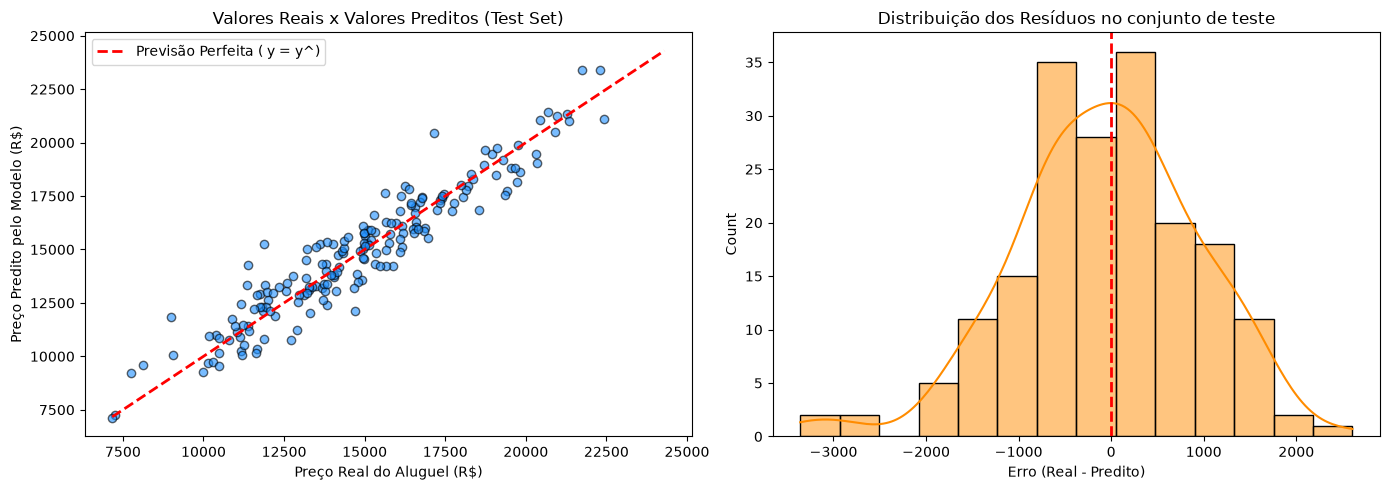

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Dispersão: Real x Predito
axes[0].scatter(y_test, y_pred, alpha=0.6, color="dodgerblue", edgecolors="k")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2, label="Previsão Perfeita ( y = y^)")
axes[0].set_title("Valores Reais x Valores Preditos (Test Set)")
axes[0].set_xlabel("Preço Real do Aluguel (R$)")
axes[0].set_ylabel("Preço Predito pelo Modelo (R$)")
axes[0].legend()

# Histograma de resíduos de Teste
residuos_teste = y_test - y_pred
sns.histplot(residuos_teste, kde=True, ax=axes[1], color="darkorange")
axes[1].axvline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Distribuição dos Resíduos no conjunto de teste")
axes[1].set_xlabel("Erro (Real - Predito)")

plt.tight_layout()
plt.show()

# <font color='blue'> Parâmetros do Modelo

In [20]:
# Coeficientes das variáveis independentes
coef_regressor_fitted = pipeline_modelo.named_steps["ridge"].coef_
coef_regressor_fitted

array([3251.41613053, -468.39559757,  460.03291845, -815.59734687])

In [21]:
# Features
features = X.columns
features

Index(['tamanho_m2', 'idade_imovel', 'num_banheiros', 'proximidade_metro'], dtype='str')

In [22]:
# DataFrame
coeficientes = pd.DataFrame({
    "variavel": features,
    "coeficiente padronizado": coef_regressor_fitted
}).sort_values(by="coeficiente padronizado", ascending=False)

display(coeficientes)

,variavel,coeficiente padronizado
0,tamanho_m2,3251.416131
2,num_banheiros,460.032918
1,idade_imovel,-468.395598
3,proximidade_metro,-815.597347


# <font color='blue'> Exportando o modelo

Exportando a Pipeline completa. <Br>
A Classe Pipeline permite criar fluxos precisos para modelos de Machine Learning e isso permite a **reprodutibilidade** do experimento em ambientes de produção.

In [23]:
# Biblioteca
import joblib

In [24]:
joblib.dump(pipeline_modelo, "pipeline_modelo.pkl")

['pipeline_modelo.pkl']